In [2]:
import pandas as pd

df = pd.read_csv("../data/himalayan_landslide_v1_dataset.csv")

print("Dataset loaded successfully")
print("Rows:", len(df))
print("Columns:", len(df.columns))

df.head()

Dataset loaded successfully
Rows: 23018
Columns: 7


,LATITUDE,LONGITUDE,ELEVATION,SLOPE,RAINFALL,LANDCOVER_CODE,LANDSLIDE
0,32.919059,75.877266,3479,39.549946,3.476299,60,1
1,32.918856,75.876429,3453,32.201588,3.476299,30,1
2,32.917961,75.876663,3409,25.235184,3.476299,60,1
3,32.916468,75.879924,3265,48.509022,3.476299,30,1
4,32.910277,75.880926,3162,52.606400,3.476299,30,1


In [3]:
print("Overall rainfall statistics:")
print(df["RAINFALL"].describe())

print("\nUnique rainfall values:", df["RAINFALL"].nunique())

print("\nRainfall statistics by class:")
print(df.groupby("LANDSLIDE")["RAINFALL"].describe())

print("\nUnique values by class:")
print(df.groupby("LANDSLIDE")["RAINFALL"].nunique())

Overall rainfall statistics:
count    23018.000000
mean         3.775170
std          1.166837
min          0.625721
25%          3.205539
50%          3.941704
75%          4.368923
max          8.566375
Name: RAINFALL, dtype: float64

Unique rainfall values: 3989

Rainfall statistics by class:
             count      mean       std       min       25%       50%  \
LANDSLIDE                                                              
0          11509.0  3.384675  1.245213  0.625721  2.431579  3.629013   
1          11509.0  4.165665  0.931441  0.806748  3.683779  4.171367   

                75%       max  
LANDSLIDE                      
0          4.213994  8.566375  
1          4.526627  8.379945  

Unique values by class:
LANDSLIDE
0    3727
1    1457
Name: RAINFALL, dtype: int64


In [3]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23018 entries, 0 to 23017
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   LATITUDE        23018 non-null  float64
 1   LONGITUDE       23018 non-null  float64
 2   ELEVATION       23018 non-null  int64  
 3   SLOPE           23018 non-null  float64
 4   RAINFALL        23018 non-null  float64
 5   LANDCOVER_CODE  23018 non-null  int64  
 6   LANDSLIDE       23018 non-null  int64  
dtypes: float64(4), int64(3)
memory usage: 1.2 MB
None


In [4]:
df.describe()

,LATITUDE,LONGITUDE,ELEVATION,SLOPE,RAINFALL,LANDCOVER_CODE,LANDSLIDE
count,23018.000000,23018.000000,23018.000000,23018.000000,23018.000000,23018.000000,23018.000000
mean,30.976283,78.075900,2061.784690,27.851241,3.775170,28.625424,0.500000
std,0.996775,1.224284,1478.075061,13.037896,1.166837,22.875478,0.500011
min,28.727639,75.609110,187.000000,0.000000,0.625721,10.000000,0.000000
25%,30.202037,77.089923,992.000000,19.389796,3.205539,10.000000,0.000000
50%,30.885260,77.980449,1565.000000,28.656198,3.941704,30.000000,0.500000
75%,31.778166,79.066273,2684.750000,36.622769,4.368923,40.000000,1.000000
max,33.166375,81.010408,6831.000000,75.853127,8.566375,100.000000,1.000000


In [5]:
df.groupby("LANDSLIDE")[["ELEVATION", "SLOPE", "RAINFALL"]].agg(
    ["mean", "median", "min", "max"]
)

ELEVATION                         SLOPE                  \
                  mean  median  min   max       mean     median  min   
LANDSLIDE                                                              
0          2719.509862  2420.0  187  6831  25.112658  25.601675  0.0   
1          1404.059519  1328.0  261  5879  30.589825  30.706944  0.0   

                      RAINFALL                                
                 max      mean    median       min       max  
LANDSLIDE                                                     
0          75.853127  3.384675  3.629013  0.625721  8.566375  
1          73.464073  4.165665  4.171367  0.806748  8.379945

<Figure size 800x500 with 0 Axes>

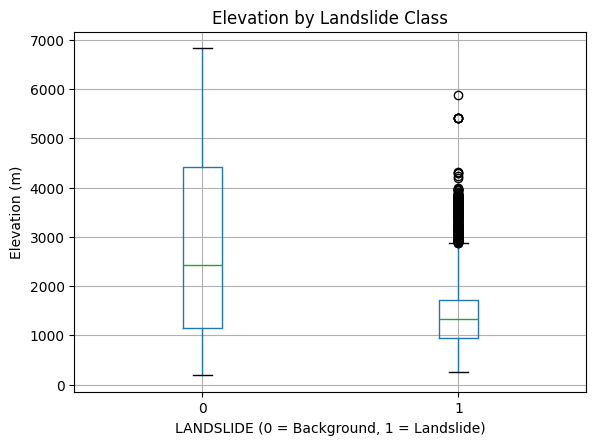

In [6]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

df.boxplot(
    column="ELEVATION",
    by="LANDSLIDE"
)

plt.title("Elevation by Landslide Class")
plt.suptitle("")
plt.xlabel("LANDSLIDE (0 = Background, 1 = Landslide)")
plt.ylabel("Elevation (m)")
plt.show()

<Figure size 800x500 with 0 Axes>

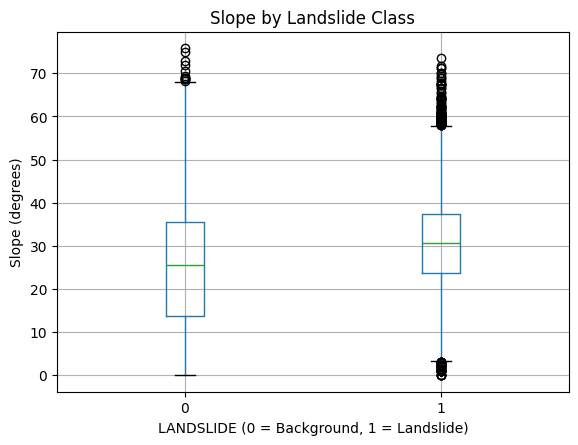

In [7]:
plt.figure(figsize=(8, 5))

df.boxplot(
    column="SLOPE",
    by="LANDSLIDE"
)

plt.title("Slope by Landslide Class")
plt.suptitle("")
plt.xlabel("LANDSLIDE (0 = Background, 1 = Landslide)")
plt.ylabel("Slope (degrees)")
plt.show()

<Figure size 800x500 with 0 Axes>

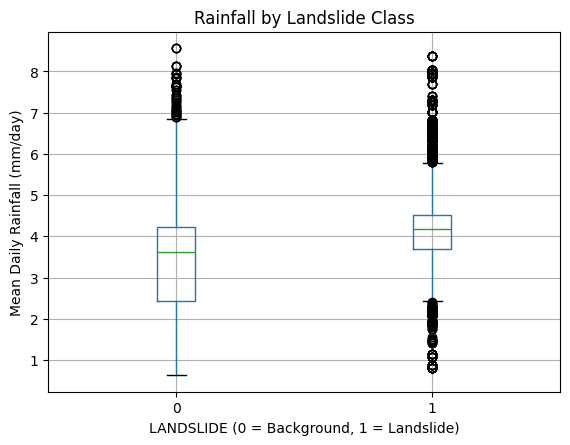

In [8]:
plt.figure(figsize=(8, 5))

df.boxplot(
    column="RAINFALL",
    by="LANDSLIDE"
)

plt.title("Rainfall by Landslide Class")
plt.suptitle("")
plt.xlabel("LANDSLIDE (0 = Background, 1 = Landslide)")
plt.ylabel("Mean Daily Rainfall (mm/day)")
plt.show()

In [9]:
landcover_counts = pd.crosstab(
    df["LANDCOVER_CODE"],
    df["LANDSLIDE"]
)

landcover_counts.columns = [
    "Background",
    "Landslide"
]

print(landcover_counts)

                Background  Landslide
LANDCOVER_CODE                       
10                    4989       6083
20                      45        196
30                    2037       3705
40                     607         67
50                      98        953
60                    1962        427
70                    1113          5
80                      95         59
90                       3          0
100                    560         14


In [10]:
landcover_names = {
    10: "Tree cover",
    20: "Shrubland",
    30: "Grassland",
    40: "Cropland",
    50: "Built-up",
    60: "Bare/sparse vegetation",
    70: "Snow/ice",
    80: "Permanent water bodies",
    90: "Herbaceous wetland",
    95: "Mangroves",
    100: "Moss/lichen"
}

landcover_counts_named = landcover_counts.copy()

landcover_counts_named.index = (
    landcover_counts_named.index.map(landcover_names)
)

print(landcover_counts_named)

                        Background  Landslide
LANDCOVER_CODE                               
Tree cover                    4989       6083
Shrubland                       45        196
Grassland                     2037       3705
Cropland                       607         67
Built-up                        98        953
Bare/sparse vegetation        1962        427
Snow/ice                      1113          5
Permanent water bodies          95         59
Herbaceous wetland               3          0
Moss/lichen                    560         14


In [11]:
landcover_percent = pd.crosstab(
    df["LANDCOVER_CODE"],
    df["LANDSLIDE"],
    normalize="columns"
) * 100

landcover_percent.columns = [
    "Background (%)",
    "Landslide (%)"
]

landcover_percent.index = (
    landcover_percent.index.map(landcover_names)
)

print(landcover_percent.round(2))

                        Background (%)  Landslide (%)
LANDCOVER_CODE                                       
Tree cover                       43.35          52.85
Shrubland                         0.39           1.70
Grassland                        17.70          32.19
Cropland                          5.27           0.58
Built-up                          0.85           8.28
Bare/sparse vegetation           17.05           3.71
Snow/ice                          9.67           0.04
Permanent water bodies            0.83           0.51
Herbaceous wetland                0.03           0.00
Moss/lichen                       4.87           0.12


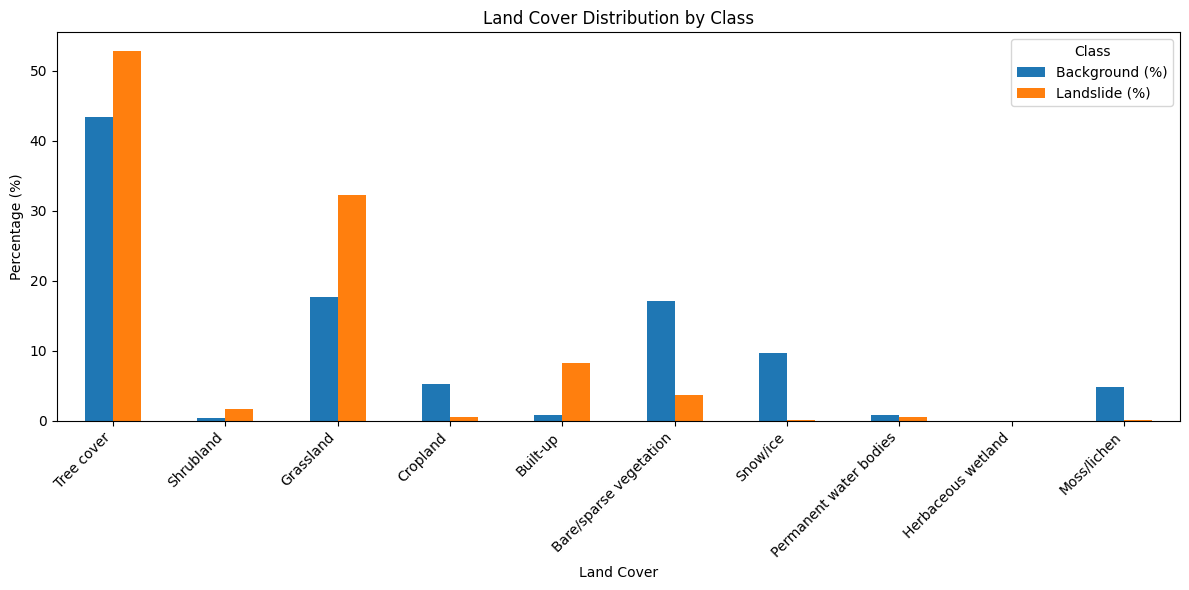

In [12]:
landcover_percent.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Land Cover Distribution by Class")
plt.xlabel("Land Cover")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Class")
plt.tight_layout()
plt.show()

In [13]:
corr = df[
    ["ELEVATION", "SLOPE", "RAINFALL", "LANDSLIDE"]
].corr()

print(corr.round(3))

           ELEVATION  SLOPE  RAINFALL  LANDSLIDE
ELEVATION      1.000  0.226    -0.665     -0.445
SLOPE          0.226  1.000    -0.147      0.210
RAINFALL      -0.665 -0.147     1.000      0.335
LANDSLIDE     -0.445  0.210     0.335      1.000


In [14]:
duplicate_coords = df.duplicated(
    subset=["LATITUDE", "LONGITUDE"]
).sum()

print("Duplicate coordinate rows:", duplicate_coords)

Duplicate coordinate rows: 705


In [15]:
# Find all rows with duplicate coordinates
duplicate_rows = df[
    df.duplicated(
        subset=["LATITUDE", "LONGITUDE"],
        keep=False
    )
].sort_values(["LATITUDE", "LONGITUDE"])

print("Rows involved in duplicate coordinates:", len(duplicate_rows))

# Check whether duplicate coordinates have different labels
conflicting = (
    duplicate_rows
    .groupby(["LATITUDE", "LONGITUDE"])["LANDSLIDE"]
    .nunique()
)

conflicting_locations = conflicting[conflicting > 1]

print("Coordinates appearing in BOTH classes:",
      len(conflicting_locations))

# Show a few examples
if len(conflicting_locations) > 0:
    print("\nExamples:")
    print(
        duplicate_rows[
            duplicate_rows.set_index(
                ["LATITUDE", "LONGITUDE"]
            ).index.isin(conflicting_locations.index)
        ].head(10)
    )

Rows involved in duplicate coordinates: 1112
Coordinates appearing in BOTH classes: 0


In [16]:
print(
    duplicate_rows["LANDSLIDE"]
    .value_counts()
    .sort_index()
)

LANDSLIDE
1    1112
Name: count, dtype: int64


In [17]:
duplicate_locations = duplicate_rows[
    ["LATITUDE", "LONGITUDE"]
].drop_duplicates()

print("Duplicate rows:", len(duplicate_rows))
print("Unique duplicate locations:", len(duplicate_locations))

print("\nRecords per duplicate location:")
print(
    duplicate_rows
    .groupby(["LATITUDE", "LONGITUDE"])
    .size()
    .value_counts()
    .sort_index()
)

Duplicate rows: 1112
Unique duplicate locations: 407

Records per duplicate location:
2     268
3      67
4      39
5      20
6       3
7       3
8       2
9       2
12      1
15      1
19      1
Name: count, dtype: int64


In [18]:
unique_locations = df[
    ["LATITUDE", "LONGITUDE"]
].drop_duplicates()

print("Total rows:", len(df))
print("Unique coordinates:", len(unique_locations))
print("Repeated rows:", len(df) - len(unique_locations))

Total rows: 23018
Unique coordinates: 22313
Repeated rows: 705


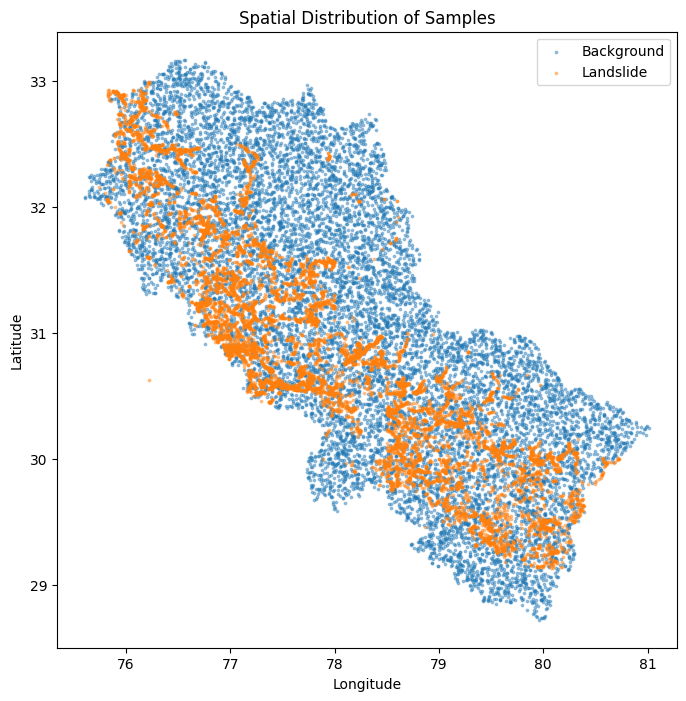

In [19]:
plt.figure(figsize=(8, 8))

plt.scatter(
    df[df["LANDSLIDE"] == 0]["LONGITUDE"],
    df[df["LANDSLIDE"] == 0]["LATITUDE"],
    s=3,
    alpha=0.4,
    label="Background"
)

plt.scatter(
    df[df["LANDSLIDE"] == 1]["LONGITUDE"],
    df[df["LANDSLIDE"] == 1]["LATITUDE"],
    s=3,
    alpha=0.4,
    label="Landslide"
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Spatial Distribution of Samples")
plt.legend()
plt.show()

In [20]:
print("Latitude range:",
      df["LATITUDE"].min(),
      "to",
      df["LATITUDE"].max())

print("Longitude range:",
      df["LONGITUDE"].min(),
      "to",
      df["LONGITUDE"].max())

Latitude range: 28.727638520868283 to 33.16637488977268
Longitude range: 75.60910965105909 to 81.0104078485408


In [21]:
# Test several spatial block sizes
block_sizes = [0.25, 0.5, 1.0]

for size in block_sizes:

    temp = df.copy()

    temp["BLOCK_LAT"] = (
        (temp["LATITUDE"] / size).astype(int)
    )

    temp["BLOCK_LON"] = (
        (temp["LONGITUDE"] / size).astype(int)
    )

    temp["BLOCK_ID"] = (
        temp["BLOCK_LAT"].astype(str)
        + "_"
        + temp["BLOCK_LON"].astype(str)
    )

    block_summary = (
        temp.groupby("BLOCK_ID")
        .agg(
            samples=("LANDSLIDE", "size"),
            landslides=("LANDSLIDE", "sum")
        )
    )

    block_summary["background"] = (
        block_summary["samples"]
        - block_summary["landslides"]
    )

    print("\n" + "=" * 60)
    print(f"BLOCK SIZE: {size} degrees")
    print("=" * 60)

    print("Number of blocks:", len(block_summary))
    print("Smallest block:", block_summary["samples"].min())
    print("Largest block:", block_summary["samples"].max())
    print(
        "Blocks containing both classes:",
        (
            (block_summary["landslides"] > 0)
            & (block_summary["background"] > 0)
        ).sum()
    )


BLOCK SIZE: 0.25 degrees
Number of blocks: 202
Smallest block: 1
Largest block: 476
Blocks containing both classes: 127

BLOCK SIZE: 0.5 degrees
Number of blocks: 62
Smallest block: 1
Largest block: 1221
Blocks containing both classes: 47

BLOCK SIZE: 1.0 degrees
Number of blocks: 22
Smallest block: 1
Largest block: 2846
Blocks containing both classes: 16


In [22]:
from sklearn.model_selection import StratifiedGroupKFold

df_spatial = df.copy()

block_size = 0.5

df_spatial["BLOCK_LAT"] = (
    df_spatial["LATITUDE"] / block_size
).astype(int)

df_spatial["BLOCK_LON"] = (
    df_spatial["LONGITUDE"] / block_size
).astype(int)

df_spatial["BLOCK_ID"] = (
    df_spatial["BLOCK_LAT"].astype(str)
    + "_"
    + df_spatial["BLOCK_LON"].astype(str)
)

X = df_spatial.drop(columns=["LANDSLIDE"])
y = df_spatial["LANDSLIDE"]
groups = df_spatial["BLOCK_ID"]

cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

for fold, (train_idx, test_idx) in enumerate(
    cv.split(X, y, groups),
    start=1
):
    train_y = y.iloc[train_idx]
    test_y = y.iloc[test_idx]

    print(f"\nFold {fold}")
    print("Train samples:", len(train_idx))
    print("Test samples :", len(test_idx))
    print("Train classes:", train_y.value_counts().to_dict())
    print("Test classes :", test_y.value_counts().to_dict())

    train_groups = set(groups.iloc[train_idx])
    test_groups = set(groups.iloc[test_idx])

    print(
        "Overlapping spatial blocks:",
        len(train_groups & test_groups)
    )


Fold 1
Train samples: 18254
Test samples : 4764
Train classes: {0: 9227, 1: 9027}
Test classes : {1: 2482, 0: 2282}
Overlapping spatial blocks: 0

Fold 2
Train samples: 18487
Test samples : 4531
Train classes: {1: 9335, 0: 9152}
Test classes : {0: 2357, 1: 2174}
Overlapping spatial blocks: 0

Fold 3
Train samples: 18802
Test samples : 4216
Train classes: {1: 10013, 0: 8789}
Test classes : {0: 2720, 1: 1496}
Overlapping spatial blocks: 0

Fold 4
Train samples: 18403
Test samples : 4615
Train classes: {0: 9279, 1: 9124}
Test classes : {1: 2385, 0: 2230}
Overlapping spatial blocks: 0

Fold 5
Train samples: 18126
Test samples : 4892
Train classes: {0: 9589, 1: 8537}
Test classes : {1: 2972, 0: 1920}
Overlapping spatial blocks: 0


In [23]:
for fold, (train_idx, test_idx) in enumerate(
    cv.split(X, y, groups),
    start=1
):
    train_groups = set(groups.iloc[train_idx])
    test_groups = set(groups.iloc[test_idx])

    print(
        f"Fold {fold}: "
        f"Train={len(train_idx)}, "
        f"Test={len(test_idx)}, "
        f"Train_1={y.iloc[train_idx].sum()}, "
        f"Test_1={y.iloc[test_idx].sum()}, "
        f"Block_overlap={len(train_groups & test_groups)}"
    )

Fold 1: Train=18254, Test=4764, Train_1=9027, Test_1=2482, Block_overlap=0
Fold 2: Train=18487, Test=4531, Train_1=9335, Test_1=2174, Block_overlap=0
Fold 3: Train=18802, Test=4216, Train_1=10013, Test_1=1496, Block_overlap=0
Fold 4: Train=18403, Test=4615, Train_1=9124, Test_1=2385, Block_overlap=0
Fold 5: Train=18126, Test=4892, Train_1=8537, Test_1=2972, Block_overlap=0


In [24]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

# Features used by the model
numeric_features = [
    "ELEVATION",
    "SLOPE",
    "RAINFALL"
]

categorical_features = [
    "LANDCOVER_CODE"
]

# Preprocessing for numerical features
numeric_transformer = Pipeline(
    steps=[
        ("scaler", StandardScaler())
    ]
)

# Preprocessing for land cover
categorical_transformer = Pipeline(
    steps=[
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore"
            )
        )
    ]
)

# Combine both preprocessing methods
preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            numeric_transformer,
            numeric_features
        ),
        (
            "categorical",
            categorical_transformer,
            categorical_features
        )
    ]
)

# Logistic Regression baseline
logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            LogisticRegression(
                max_iter=1000,
                random_state=42
            )
        )
    ]
)

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.
